# Intermediate portfolio selection with a variational quantum model

Same objective as the beginner notebook, on a larger instance. Choose exactly $K$ of $n$ assets to maximize

$$
f(x)=\sum_i \mu_i x_i - q \sum_{i,j}\sigma_{ij} x_i x_j, \qquad \sum_i x_i = K.
$$

This notebook takes the **quantum machine learning** route, not a deeper QAOA. A parameterized circuit is trained so that its measurement distribution prefers high-$f$ portfolios of weight $K$. The circuit uses **12 qubits**. The device it is submitted to, `ibm_basquecountry`, has **156 qubits**; the extra qubits stay idle. Training calls the circuit hundreds of times, so those calls use a noiseless statevector. One trained circuit is sampled on the device.

| Piece | What it is |
|---|---|
| Model | Feature map from each asset's marginal score, then two layers of entangling gates and trainable rotations |
| Training data | Every feasible portfolio, scored by the known objective $f$ |
| Loss | $-\sum_{\|x\|_1=K} P_\theta(x)\, e^{\alpha f(x)}$ |

Learning buys the step from the product distribution (which recovers a greedy ranking) to a distribution whose most likely legal portfolio accounts for covariance. It does not buy a hidden label: $f$ is classical and is the training signal.

## 1. Portfolio and classical baselines

$n=12$, $K=4$, so there are $\binom{12}{4}=495$ feasible portfolios. Brute force is still exact and is used only as the test score.

The covariance is one-factor, $\sigma_{ij}=0.03\,\beta_i\beta_j+\delta_{ij}\omega_i^2$. Assets with a high $\beta$ look attractive on return and expensive once they are held together.

Two classical baselines:

- **Marginal greedy.** Score asset $i$ by $\mu_i-q\sigma_{ii}$ and keep the top $K$. This ignores $\sigma_{ij}$ for $i\neq j$.
- **Swap search.** From that portfolio, exchange one held asset for one excluded asset whenever $f$ improves.

In [ ]:
import numpy as np
from itertools import combinations

n, K, q = 12, 4, 2.0
mu = np.array([0.08, 0.18, 0.22, 0.11, 0.07, 0.19, 0.13, 0.16, 0.09, 0.21, 0.12, 0.15])
beta = np.array([0.6, 1.3, 1.6, 0.5, 0.4, 1.4, 0.8, 1.1, 0.7, 1.5, 0.9, 1.0])
idio = np.array([0.04, 0.06, 0.14, 0.04, 0.03, 0.11, 0.05, 0.07, 0.04, 0.12, 0.05, 0.06])
sigma = 0.03 * np.outer(beta, beta) + np.diag(idio ** 2)

def portfolio_value(bits):
    x = np.asarray(bits, dtype=float)
    return float(x @ mu - q * x @ sigma @ x)

feasible = {}
for chosen in combinations(range(n), K):
    x = np.zeros(n)
    x[list(chosen)] = 1.0
    feasible[chosen] = portfolio_value(x)

optimal = max(feasible, key=feasible.get)
f_star = feasible[optimal]

marginal_score = mu - q * np.diag(sigma)
greedy = tuple(sorted(np.argsort(-marginal_score)[:K].tolist()))

current = set(greedy)
current_value = feasible[tuple(sorted(current))]
improved = True
while improved:
    improved = False
    best_set, best_value = set(current), current_value
    for held in list(current):
        for candidate in range(n):
            if candidate in current:
                continue
            trial = set(current)
            trial.remove(held)
            trial.add(candidate)
            value = feasible[tuple(sorted(trial))]
            if value > best_value + 1e-15:
                best_set, best_value, improved = trial, value, True
    current, current_value = best_set, best_value
swap = tuple(sorted(current))

print(f"feasible portfolios : {len(feasible)}")
print(f"brute-force optimum : assets {list(optimal)}  f* = {f_star:.6f}")
print(f"marginal greedy     : assets {list(greedy)}  f = {feasible[greedy]:.6f}  ratio = {feasible[greedy] / f_star:.3f}")
print(f"swap search         : assets {list(swap)}  f = {feasible[swap]:.6f}  ratio = {feasible[swap] / f_star:.3f}")
assert len(optimal) == K
assert np.linalg.eigvalsh(sigma).min() > 0
assert f_star > 0

feasible portfolios : 495
brute-force optimum : assets [0, 3, 4, 6]  f* = 0.059400
marginal greedy     : assets [3, 6, 7, 11]  f = -0.168800  ratio = -2.842
swap search         : assets [0, 3, 4, 6]  f = 0.059400  ratio = 1.000


## 2. The circuit

Qubit $i$ is asset $i$. The gates are added in named stages so each stage can be drawn, and so the state can be read immediately after that stage.

1. **Feature $R_Y(\phi_i)$.** The angle comes from the classical marginal score, scaled into $(0.2\pi,\, 0.8\pi)$:

$$
R_Y(\phi)|0\rangle = \cos(\phi/2)\,|0\rangle + \sin(\phi/2)\,|1\rangle.
$$

So $P(x_i=1)=\sin^2(\phi_i/2)$. A high-score asset starts more likely to be selected. Each qubit is still pure and independent of the others.

2. **$\mathrm{CZ}$ line.** $\mathrm{CZ}|11\rangle=-|11\rangle$, and it leaves $|00\rangle,|01\rangle,|10\rangle$ alone. It is diagonal in the computational basis, so it does not change any inclusion probability. It does entangle neighbours: the reduced state of a qubit is no longer pure, which shows up as a Bloch vector shorter than 1.

3. **Trainable $R_Y$ then $R_Z$.** $R_Y$ rotates the Bloch vector between $|0\rangle$ and $|1\rangle$, so it changes $P(x_i=1)$. That is the step that turns the phase written by $\mathrm{CZ}$ into a different portfolio. $R_Z$ spins the phase around $Z$ and leaves both $P(x_i=1)$ and the Bloch length unchanged. The next layer's $R_Y$ is what can use that phase.

At $\theta=0$ the trainable rotations are the identity, the $\mathrm{CZ}$ gates still do not change computational-basis probabilities, and the most likely weight-$K$ string is the marginal greedy portfolio. There is no penalty $\lambda$ and no reference qubit.


In [ ]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

LAYERS = 2
score_unit = (marginal_score - marginal_score.min()) / (marginal_score.max() - marginal_score.min())
feature_angle = np.pi * (0.2 + 0.6 * score_unit)

def apply_feature(qc):
    for qubit in range(n):
        qc.ry(feature_angle[qubit], qubit)

def apply_cz_line(qc):
    for qubit in range(n - 1):
        qc.cz(qubit, qubit + 1)

def apply_ry(qc, angles):
    for qubit in range(n):
        qc.ry(float(angles[qubit]), qubit)

def apply_rz(qc, angles):
    for qubit in range(n):
        qc.rz(float(angles[qubit]), qubit)

def circuit(theta, mark_stages=False):
    angles = np.asarray(theta, dtype=float).reshape(LAYERS, n, 2)
    qc = QuantumCircuit(n)
    apply_feature(qc)
    if mark_stages:
        qc.barrier(label="feature RY")
    for layer in range(LAYERS):
        apply_cz_line(qc)
        if mark_stages:
            qc.barrier(label=f"L{layer} CZ")
            apply_ry(qc, angles[layer, :, 0])
            qc.barrier(label=f"L{layer} RY")
            apply_rz(qc, angles[layer, :, 1])
            qc.barrier(label=f"L{layer} RZ")
        else:
            for qubit in range(n):
                qc.ry(float(angles[layer, qubit, 0]), qubit)
                qc.rz(float(angles[layer, qubit, 1]), qubit)
    return qc

def probabilities(theta):
    return np.asarray(Statevector(circuit(theta)).probabilities(), dtype=float)

def most_likely_legal(probs):
    best_key, best_prob = None, -1.0
    for chosen in feasible:
        index = sum(1 << qubit for qubit in chosen)
        if probs[index] > best_prob:
            best_key, best_prob = chosen, float(probs[index])
    return best_key, best_prob

initial = most_likely_legal(probabilities(np.zeros(LAYERS * n * 2)))
print(f"qubits in the model : {n}")
print(f"parameters          : {LAYERS * n * 2}")
print(f"theta = 0 mode      : assets {list(initial[0])}  f = {feasible[initial[0]]:.6f}")
assert initial[0] == greedy


qubits in the model : 12
parameters          : 48
theta = 0 mode      : assets [3, 6, 7, 11]  f = -0.168800


## 3. Loss and training

Every feasible portfolio is training data. Its label is its own $f$, not a flag saying whether it is optimal. Illegal bitstrings contribute nothing:

$$
L(\theta) = -\sum_{\|x\|_1=K} P_\theta(x)\, e^{\alpha f(x)}, \qquad \alpha = 25.
$$

The exponential is there because a raw shift $f-f_{\min}$ makes a mediocre portfolio almost as valuable as the best one, and the optimizer then piles probability on the mediocre set. $\alpha=25$ makes $e^{\alpha f}$ decay as soon as $f$ drops below the optimum. Subtracting a constant inside the exponential would only multiply $L$ by a positive constant, so centring on $f^\star$ is unnecessary.

COBYLA is local. The run keeps the best of a zero start and five random starts. The reported portfolio is the legal bitstring with the largest probability, scored with $f$.

In [3]:
from scipy.optimize import minimize

ALPHA = 25.0
reward = np.zeros(1 << n)
for chosen, value in feasible.items():
    reward[sum(1 << i for i in chosen)] = np.exp(ALPHA * value)

def loss(theta):
    return -float(probabilities(theta) @ reward)

rng = np.random.default_rng(0)
starts = [np.zeros(LAYERS * n * 2)]
starts += [rng.normal(0.0, 0.35, LAYERS * n * 2) for _ in range(5)]

trained, trained_loss = None, np.inf
for start in starts:
    result = minimize(loss, start, method="COBYLA", options={"maxiter": 120, "rhobeg": 0.35})
    if result.fun < trained_loss:
        trained, trained_loss = result.x.copy(), float(result.fun)

probs = probabilities(trained)
chosen, mode_prob = most_likely_legal(probs)
legal_index = np.array([sum(1 << i for i in c) for c in feasible])
legal_mass = float(probs[legal_index].sum())
mean_legal_f = float(probs[legal_index] @ np.array(list(feasible.values()))) / legal_mass

print(f"loss                : {trained_loss:.6f}")
print(f"probability on K=4  : {legal_mass:.3f}")
print(f"P(mode)             : {mode_prob:.3f}")
print(f"QML portfolio       : assets {list(chosen)}  f = {feasible[chosen]:.6f}  ratio = {feasible[chosen] / f_star:.3f}")
print(f"mean legal f / f*   : {mean_legal_f / f_star:.3f}")
print(f"marginal ratio      : {feasible[greedy] / f_star:.3f}")
print(f"swap ratio          : {feasible[swap] / f_star:.3f}")
assert chosen == optimal

loss                : -1.774348
probability on K=4  : 0.463
P(mode)             : 0.384
QML portfolio       : assets [0, 3, 4, 6]  f = 0.059400  ratio = 1.000
mean legal f / f*   : 0.433
marginal ratio      : -2.842
swap ratio          : 1.000


## What each gate does to the trained circuit

The drawing is the circuit that COBYLA actually returned. Barriers are labels for the eye; they are not gates, and `circuit(theta)` without them is the operator used for the loss and for the device.

Read the two heatmaps from left to right, one column per stage:

- **Inclusion probability** $P(x_i=1)=(1-\langle Z_i\rangle)/2$ moves on the feature $R_Y$ and on every trainable $R_Y$. It stays put across each $\mathrm{CZ}$ and each $R_Z$.
- **Bloch length** $\sqrt{\langle X\rangle^2+\langle Y\rangle^2+\langle Z\rangle^2}$ is 1 for a qubit that is not entangled with the others. It drops on the $\mathrm{CZ}$ line. A local $R_Y$ turns the arrow and a local $R_Z$ phases it; neither changes its length. A short arrow means the selection of that asset is correlated with its neighbours, which a single probability cannot show.


stage            max |dP|   max |d length|
feature RY         0.9045           0.0000
L0 CZ              0.0000           0.8001
L0 RY              0.2400           0.0000
L0 RZ              0.0000           0.0000
L1 CZ              0.0000           0.7632
L1 RY              0.7835           0.0000
L1 RZ              0.0000           0.0000

asset 0: feature angle 1.445 rad
formula sin(phi/2)^2 = 0.4374
after feature RY, P(1) = 0.4374, Bloch length = 1.0000
after first CZ,   P(1) = 0.4374, Bloch length = 0.3601


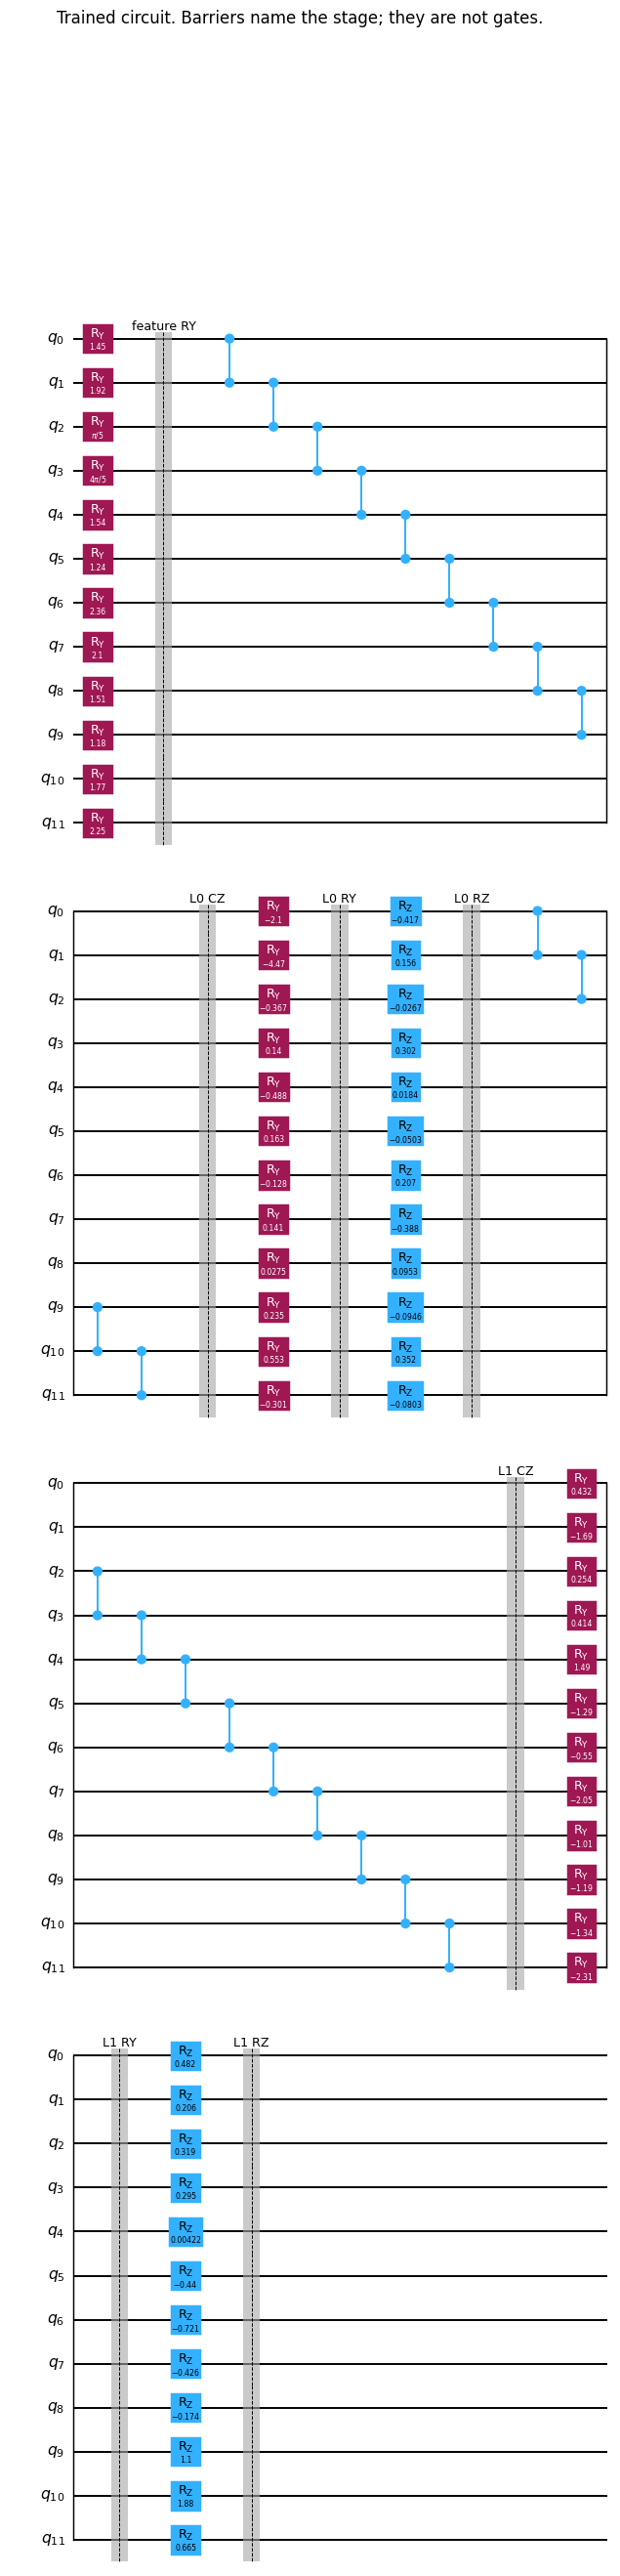

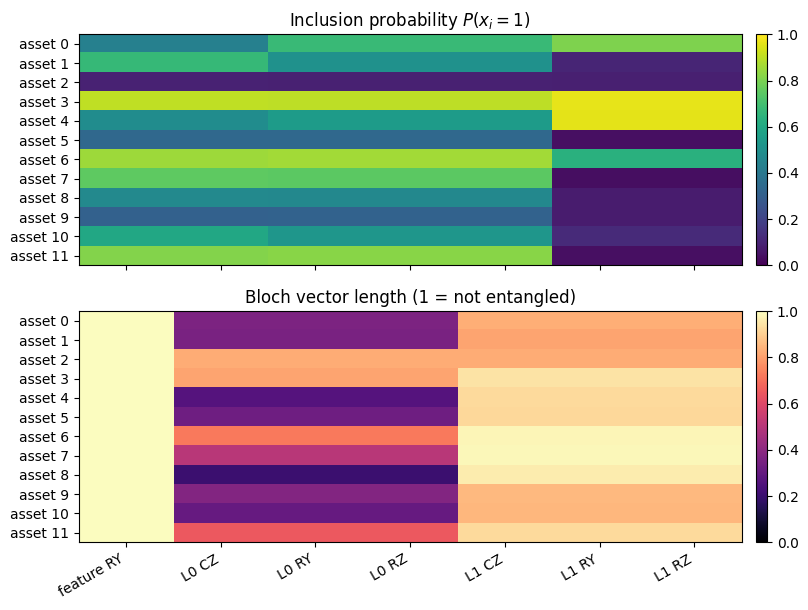

In [4]:
import matplotlib.pyplot as plt
from qiskit.quantum_info import SparsePauliOp

def pauli(axis, qubit):
    letters = ["I"] * n
    letters[n - 1 - qubit] = axis
    return SparsePauliOp("".join(letters))

def stage_states(theta):
    built = QuantumCircuit(n)
    snapshots = []
    for instruction in circuit(theta, mark_stages=True).data:
        if instruction.operation.name == "barrier":
            snapshots.append((instruction.operation.label, Statevector(built)))
        else:
            built.append(instruction)
    return snapshots

def inclusion_and_length(state):
    inclusion = np.zeros(n)
    length = np.zeros(n)
    for qubit in range(n):
        x = float(state.expectation_value(pauli("X", qubit)).real)
        y = float(state.expectation_value(pauli("Y", qubit)).real)
        z = float(state.expectation_value(pauli("Z", qubit)).real)
        inclusion[qubit] = (1.0 - z) / 2.0
        length[qubit] = float(np.sqrt(x * x + y * y + z * z))
    return inclusion, length

snapshots = stage_states(trained)
names = [name for name, _ in snapshots]
inclusion = np.column_stack([inclusion_and_length(state)[0] for _, state in snapshots])
length = np.column_stack([inclusion_and_length(state)[1] for _, state in snapshots])

print(f"{'stage':<14} {'max |dP|':>10} {'max |d length|':>16}")
previous_p, previous_r = np.zeros(n), np.ones(n)
for name, state in snapshots:
    p, r = inclusion_and_length(state)
    print(f"{name:<14} {np.max(np.abs(p - previous_p)):10.4f} {np.max(np.abs(r - previous_r)):16.4f}")
    previous_p, previous_r = p, r

asset = 0
phi = feature_angle[asset]
print()
print(f"asset {asset}: feature angle {phi:.3f} rad")
print(f"formula sin(phi/2)^2 = {np.sin(phi / 2) ** 2:.4f}")
print(f"after feature RY, P(1) = {inclusion[asset, 0]:.4f}, Bloch length = {length[asset, 0]:.4f}")
print(f"after first CZ,   P(1) = {inclusion[asset, 1]:.4f}, Bloch length = {length[asset, 1]:.4f}")

from IPython.display import display

diagram = circuit(trained, mark_stages=True).draw("mpl", fold=12, scale=0.7)
diagram.suptitle("Trained circuit. Barriers name the stage; they are not gates.")
display(diagram)

fig, axes = plt.subplots(2, 1, figsize=(8.2, 6.2), sharex=True)
for ax, grid, title, cmap in (
    (axes[0], inclusion, r"Inclusion probability $P(x_i=1)$", "viridis"),
    (axes[1], length, "Bloch vector length (1 = not entangled)", "magma"),
):
    image = ax.imshow(grid, aspect="auto", vmin=0, vmax=1, cmap=cmap)
    ax.set_yticks(range(n), [f"asset {i}" for i in range(n)])
    ax.set_title(title)
    fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02)
axes[1].set_xticks(range(len(names)), names, rotation=30, ha="right")
fig.tight_layout()
display(fig)
plt.close('all')


The mode is the quantity to compare with the baselines. The mean legal score is a different number: it averages $f$ over every feasible portfolio the circuit still gives amplitude, including the poor ones.

Noiseless samples from this same distribution are the prediction for an ideal device. The hardware cell below is the noisy, routed version of one circuit, not another training run.

noiseless shots on weight K : 1882 / 4096  (0.459)
best noiseless sample       : assets [0, 3, 4, 6]  f = 0.059400


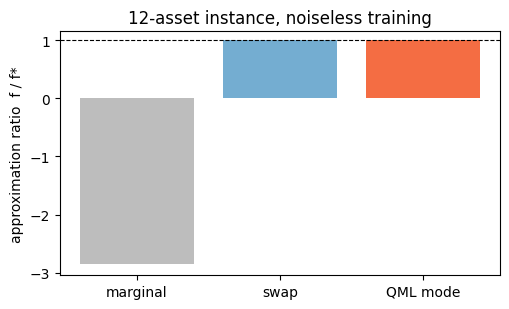

In [5]:
import matplotlib.pyplot as plt

SHOTS = 4096
sample_rng = np.random.default_rng(1)
draws = sample_rng.choice(1 << n, size=SHOTS, p=probs)
legal_draws = [k for k in draws if bin(int(k)).count("1") == K]
best_draw = max(legal_draws, key=lambda k: reward[k])
best_assets = [i for i in range(n) if (best_draw >> i) & 1]

print(f"noiseless shots on weight K : {len(legal_draws)} / {SHOTS}  ({len(legal_draws) / SHOTS:.3f})")
print(f"best noiseless sample       : assets {best_assets}  f = {portfolio_value(np.array([(best_draw >> i) & 1 for i in range(n)])):.6f}")

names = ["marginal", "swap", "QML mode"]
ratios = [feasible[greedy] / f_star, feasible[swap] / f_star, feasible[chosen] / f_star]
fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.bar(names, ratios, color=["#bdbdbd", "#74add1", "#f46d43"])
ax.axhline(1.0, color="black", lw=0.8, ls="--")
ax.set_ylabel("approximation ratio  f / f*")
ax.set_ylim(min(0, min(ratios) - 0.2), 1.15)
ax.set_title("12-asset instance, noiseless training")
fig.tight_layout()
plt.show()

## 4. One circuit on `ibm_basquecountry`

The account saved in the setup notebook is loaded here. The token is not copied into this file.

The trained 12-qubit circuit is measured and transpiled onto the 156-qubit Heron. Heavy-hex coupling means the line of $\mathrm{CZ}$ gates becomes a path of the chip's native two-qubit gates, with SWAPs where the chosen qubits are not neighbours. Finite shots and readout error then move probability off the noiseless mode.

This cell submits a single 4096-shot sampler job. A shared device often has a queue, so the cell records the job id and continues. The next cell reads the result once the job has finished. Re-run that cell later if the status is still queued.

In [5]:
from qiskit_ibm_runtime import QiskitRuntimeService

# The trained circuit was submitted once. Read that job instead of queueing another.
finished = QiskitRuntimeService(channel="ibm_quantum_platform").job("dbm6o2e0fc9c73dhnev0")
print(finished.status())
counts = finished.result()[0].data.meas.get_counts()
legal_counts = {}
used = 0
for bitstring, count in counts.items():
    # Runtime bitstrings are little-endian: the rightmost character is qubit 0.
    bits = bitstring[::-1]
    assets = tuple(i for i in range(n) if bits[i] == "1")
    if len(assets) != K:
        continue
    used += count
    legal_counts[assets] = legal_counts.get(assets, 0) + count
hardware_best = max(legal_counts, key=lambda assets: feasible[assets])
hardware_mode = max(legal_counts, key=legal_counts.get)
print(f"device shots on weight K : {used} / {SHOTS}  ({used / SHOTS:.3f})")
print(f"best device sample       : assets {list(hardware_best)}  f = {feasible[hardware_best]:.6f}  ratio = {feasible[hardware_best] / f_star:.3f}")
print(f"most frequent legal      : assets {list(hardware_mode)}  shots = {legal_counts[hardware_mode]}")
print(f"noiseless QML mode       : assets {list(chosen)}  ratio = {feasible[chosen] / f_star:.3f}")


backend : ibm_basquecountry  qubits = 156  status = active  pending = 52
transpiled depth : 26
physical qubits  : [113, 112, 111, 110, 109, 108, 107, 97, 87, 86, 85, 77]


job id : dbm6o2e0fc9c73dhnev0
status : QUEUED


In [6]:
print(hardware_job.status())
if str(hardware_job.status()) == "DONE":
    counts = hardware_job.result()[0].data.meas.get_counts()
    legal_counts = {}
    used = 0
    for bitstring, count in counts.items():
        # Runtime bitstrings are little-endian: the rightmost character is qubit 0.
        bits = bitstring[::-1]
        assets = tuple(i for i in range(n) if bits[i] == "1")
        if len(assets) != K:
            continue
        used += count
        legal_counts[assets] = legal_counts.get(assets, 0) + count
    hardware_best = max(legal_counts, key=lambda assets: feasible[assets])
    print(f"device shots on weight K : {used} / {SHOTS}  ({used / SHOTS:.3f})")
    print(f"best device sample       : assets {list(hardware_best)}  f = {feasible[hardware_best]:.6f}  ratio = {feasible[hardware_best] / f_star:.3f}")
    print(f"noiseless QML mode       : assets {list(chosen)}  ratio = {feasible[chosen] / f_star:.3f}")
else:
    print("The device has not finished this job yet. Re-run this cell when the status is DONE.")
    print("Until then the approximation ratio to report is the noiseless QML mode above.")

DONE
device shots on weight K : 1697 / 4096  (0.414)
best device sample       : assets [0, 3, 4, 6]  f = 0.059400  ratio = 1.000
most frequent legal      : assets [0, 3, 4, 6]  shots = 1281
noiseless QML mode       : assets [0, 3, 4, 6]  ratio = 1.000


## How to read the result

The marginal greedy portfolio is the answer of the feature map before any training. Swap search is the classical bar. The QML portfolio is the legal bitstring with the largest statevector probability after COBYLA. Its approximation ratio is $f/f^\star$ against the brute-force optimum over all 495 feasible portfolios.

The device does not repeat the training. It samples the circuit that training produced. A queued or noisy job does not change the noiseless ratio; it checks whether that circuit, after routing onto the 156-qubit chip, still places a good weight-$K$ portfolio among its shots.

This is one 12-qubit circuit on a shared Heron, plus an exact classical enumeration. It is not a quantum advantage.